
# Forecasting Exchange Rates using Time Series Analysis
**USD to Australian Dollar — ARIMA & Exponential Smoothing**




## Setup — Install & Import Libraries



### Part 1: Data Preparation and Exploration
1.	Data Loading: Load the exchange_rate.csv dataset and parse the date column appropriately.
2.	Initial Exploration: Plot the time series for currency to understand their trends, seasonality, and any anomalies.
3.	Data Preprocessing: Handle any missing values or anomalies identified during the exploration phase.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True
print('All libraries imported successfully!')

All libraries imported successfully!



---
## Part 1: Data Preparation and Exploration



### 1.1 Data Loading


In [ ]:
# Load the dataset — update the path if needed
df = pd.read_csv('exchange_rate.csv')

# Parse the date column (format: DD-MM-YYYY HH:MM)
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y %H:%M')
df.set_index('date', inplace=True)
df.sort_index(inplace=True)

print('Dataset loaded successfully!')
print(f'Date range : {df.index.min().date()}  →  {df.index.max().date()}')
print(f'Total rows : {len(df)}')
print(f'Columns    : {list(df.columns)}')
df.head()

Dataset loaded successfully!
Date range : 1990-01-01  →  2010-10-10
Total rows : 7588
Columns    : ['Ex_rate']


,Ex_rate
date,
1990-01-01,0.7855
1990-01-02,0.7818
1990-01-03,0.7867
1990-01-04,0.7860
1990-01-05,0.7849



### 1.2 Initial Exploration


In [ ]:
print('=== Basic Statistics ===')
print(df.describe().round(4))

=== Basic Statistics ===
         Ex_rate
count  7588.0000
mean      0.7770
std       0.1366
min       0.4833
25%       0.7014
50%       0.7614
75%       0.8735
max       1.1025


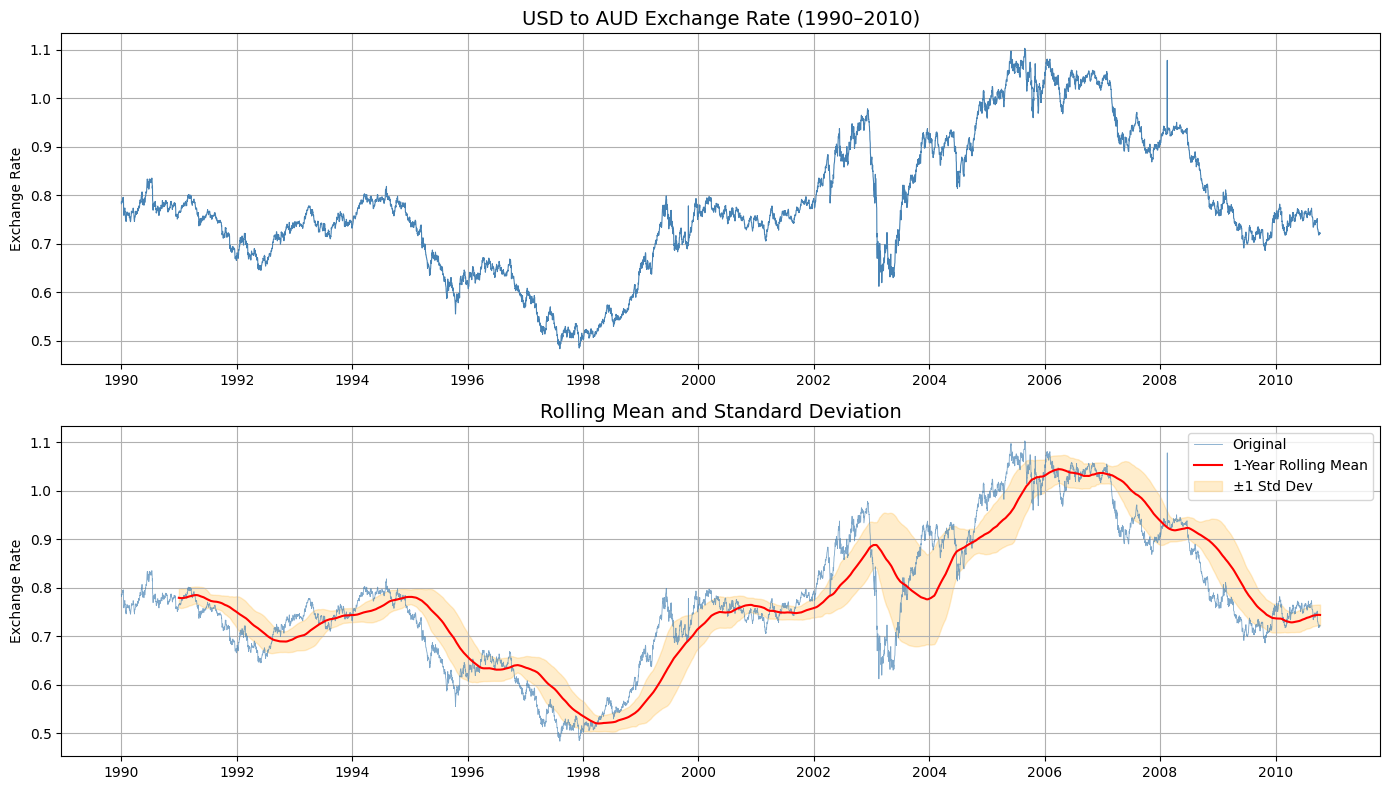


Observation: The exchange rate shows a non-stationary trend with
periods of high and low volatility, especially around 1998 and 2001.


In [ ]:
# Plot the full time series
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(df.index, df['Ex_rate'], color='steelblue', linewidth=0.8)
axes[0].set_title('USD to AUD Exchange Rate (1990–2010)', fontsize=14)
axes[0].set_ylabel('Exchange Rate')
axes[0].xaxis.set_major_locator(mdates.YearLocator(2))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Rolling mean and std to visualise trend & volatility
rolling_mean = df['Ex_rate'].rolling(window=365).mean()
rolling_std  = df['Ex_rate'].rolling(window=365).std()

axes[1].plot(df.index, df['Ex_rate'],  label='Original',         color='steelblue', linewidth=0.6, alpha=0.7)
axes[1].plot(df.index, rolling_mean,   label='1-Year Rolling Mean', color='red',    linewidth=1.5)
axes[1].fill_between(df.index,
                     rolling_mean - rolling_std,
                     rolling_mean + rolling_std,
                     alpha=0.2, color='orange', label='±1 Std Dev')
axes[1].set_title('Rolling Mean and Standard Deviation', fontsize=14)
axes[1].set_ylabel('Exchange Rate')
axes[1].legend()
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.show()

print('\nObservation: The exchange rate shows a non-stationary trend with')
print('periods of high and low volatility, especially around 1998 and 2001.')


### 1.3 Data Preprocessing — Missing Values & Anomalies


In [ ]:
print('=== Missing Value Check ===')
print(df.isnull().sum())

# Forward-fill any gaps (weekend/holiday dates)
df = df.asfreq('D')           # enforce daily frequency
df['Ex_rate'] = df['Ex_rate'].ffill()

# Check for outliers using IQR
Q1, Q3 = df['Ex_rate'].quantile([0.25, 0.75])
IQR = Q3 - Q1
outliers = df[(df['Ex_rate'] < Q1 - 3*IQR) | (df['Ex_rate'] > Q3 + 3*IQR)]
print(f'\nOutliers detected (3×IQR rule): {len(outliers)}')
print(f'Rows after resampling to daily freq: {len(df)}')

# Work with the full series for modelling
series = df['Ex_rate'].copy()
print('\nData preprocessing complete.')

=== Missing Value Check ===
Ex_rate    0
dtype: int64

Outliers detected (3×IQR rule): 0
Rows after resampling to daily freq: 7588

Data preprocessing complete.



---
## Part 2: Model Building — ARIMA



### 2.1 Stationarity Test (ADF) and Differencing


In [ ]:
def adf_test(series, label=''):
    result = adfuller(series.dropna(), autolag='AIC')
    print(f'--- ADF Test: {label} ---')
    print(f'  ADF Statistic : {result[0]:.4f}')
    print(f'  p-value       : {result[1]:.4f}')
    print(f'  Critical (5%) : {result[4]["5%"]:.4f}')
    if result[1] <= 0.05:
        print('  → Series IS stationary (reject H₀)\n')
    else:
        print('  → Series is NOT stationary (fail to reject H₀)\n')

adf_test(series, 'Original Series')
adf_test(series.diff().dropna(), '1st Difference')

--- ADF Test: Original Series ---
  ADF Statistic : -1.6650
  p-value       : 0.4492
  Critical (5%) : -2.8619
  → Series is NOT stationary (fail to reject H₀)

--- ADF Test: 1st Difference ---
  ADF Statistic : -99.3934
  p-value       : 0.0000
  Critical (5%) : -2.8619
  → Series IS stationary (reject H₀)




### 2.2 ACF and PACF Plots — ARIMA Parameter Selection


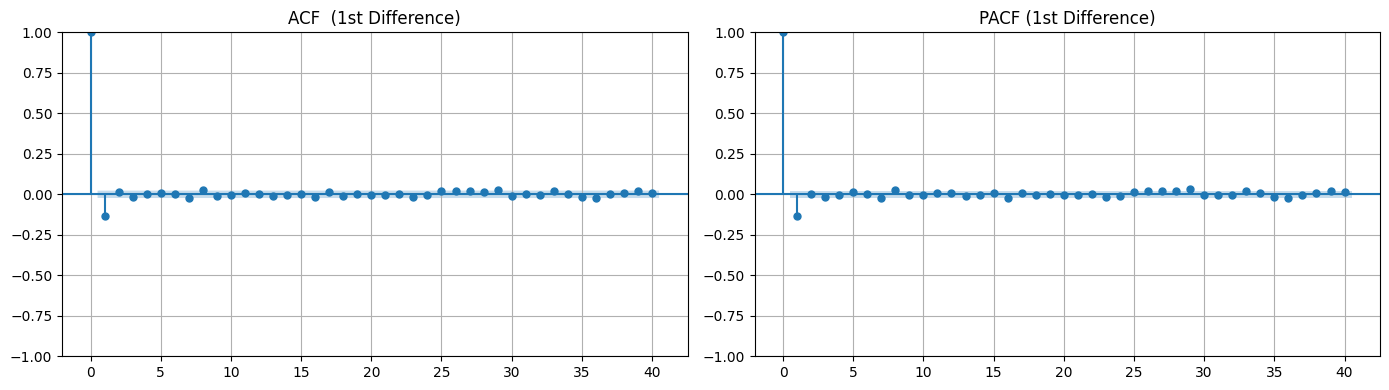

Interpretation:
  • ACF  cuts off after lag 1  → q = 1  (MA order)
  • PACF cuts off after lag 1  → p = 1  (AR order)
  • 1st differencing used      → d = 1
  Selected ARIMA order: (1, 1, 1)


In [ ]:
diff_series = series.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(diff_series,  lags=40, ax=axes[0], title='ACF  (1st Difference)')
plot_pacf(diff_series, lags=40, ax=axes[1], title='PACF (1st Difference)', method='ywm')
plt.tight_layout()
plt.show()

print('Interpretation:')
print('  • ACF  cuts off after lag 1  → q = 1  (MA order)')
print('  • PACF cuts off after lag 1  → p = 1  (AR order)')
print('  • 1st differencing used      → d = 1')
print('  Selected ARIMA order: (1, 1, 1)')


### 2.3 Train-Test Split


In [ ]:
# Use last 180 days as test set
TEST_SIZE = 180
train = series.iloc[:-TEST_SIZE]
test  = series.iloc[-TEST_SIZE:]

print(f'Training set : {train.index[0].date()} to {train.index[-1].date()}  ({len(train)} obs)')
print(f'Test set     : {test.index[0].date()}  to {test.index[-1].date()}   ({len(test)} obs)')

Training set : 1990-01-01 to 2010-04-13  (7408 obs)
Test set     : 2010-04-14  to 2010-10-10   (180 obs)



### 2.4 Fit ARIMA(1,1,1)


In [ ]:
print('Fitting ARIMA(1,1,1) ...')
arima_model = ARIMA(train, order=(1, 1, 1))
arima_fit   = arima_model.fit()
print(arima_fit.summary())

Fitting ARIMA(1,1,1) ...
                               SARIMAX Results                                
Dep. Variable:                Ex_rate   No. Observations:                 7408
Model:                 ARIMA(1, 1, 1)   Log Likelihood               27334.640
Date:                Thu, 04 Jun 2026   AIC                         -54663.280
Time:                        08:13:32   BIC                         -54642.549
Sample:                    01-01-1990   HQIC                        -54656.156
                         - 04-13-2010                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1229      0.046     -2.683      0.007      -0.213      -0.033
ma.L1         -0.0093      0.046     -0.202      0.840      -0.099       0.081
sigma2      3.648e-05   1.0


### 2.5 ARIMA Residual Diagnostics


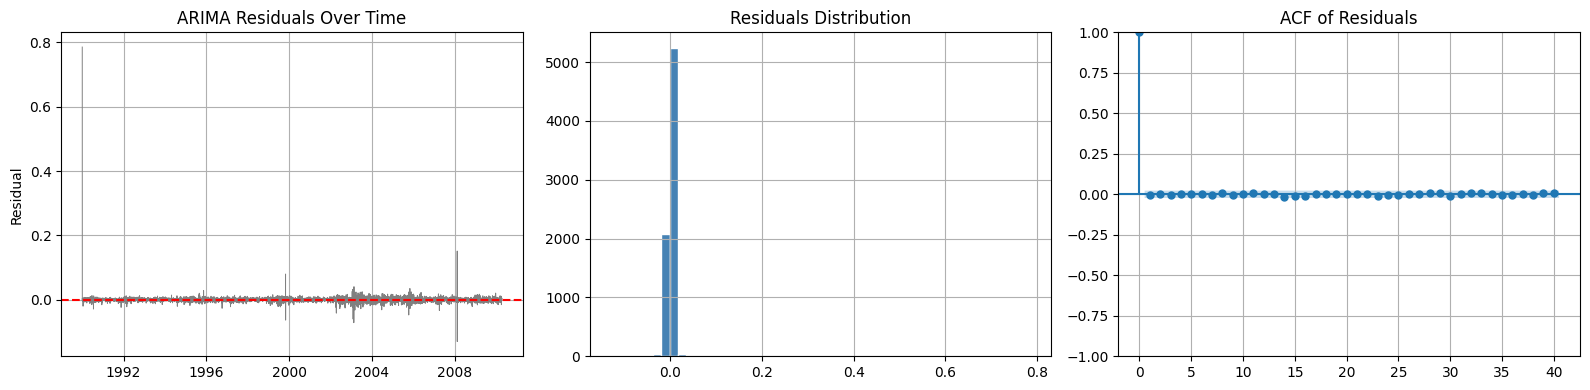

Residual mean : 0.000101  (close to 0 is good)
Residual std  : 0.010944

If ACF bars are within the blue band, residuals are white noise — good fit!


In [ ]:
residuals = arima_fit.resid

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(residuals, color='grey', linewidth=0.7)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('ARIMA Residuals Over Time')
axes[0].set_ylabel('Residual')

axes[1].hist(residuals, bins=50, color='steelblue', edgecolor='white')
axes[1].set_title('Residuals Distribution')

plot_acf(residuals, lags=40, ax=axes[2], title='ACF of Residuals')

plt.tight_layout()
plt.show()

print(f'Residual mean : {residuals.mean():.6f}  (close to 0 is good)')
print(f'Residual std  : {residuals.std():.6f}')
print('\nIf ACF bars are within the blue band, residuals are white noise — good fit!')


### 2.6 ARIMA Forecasting


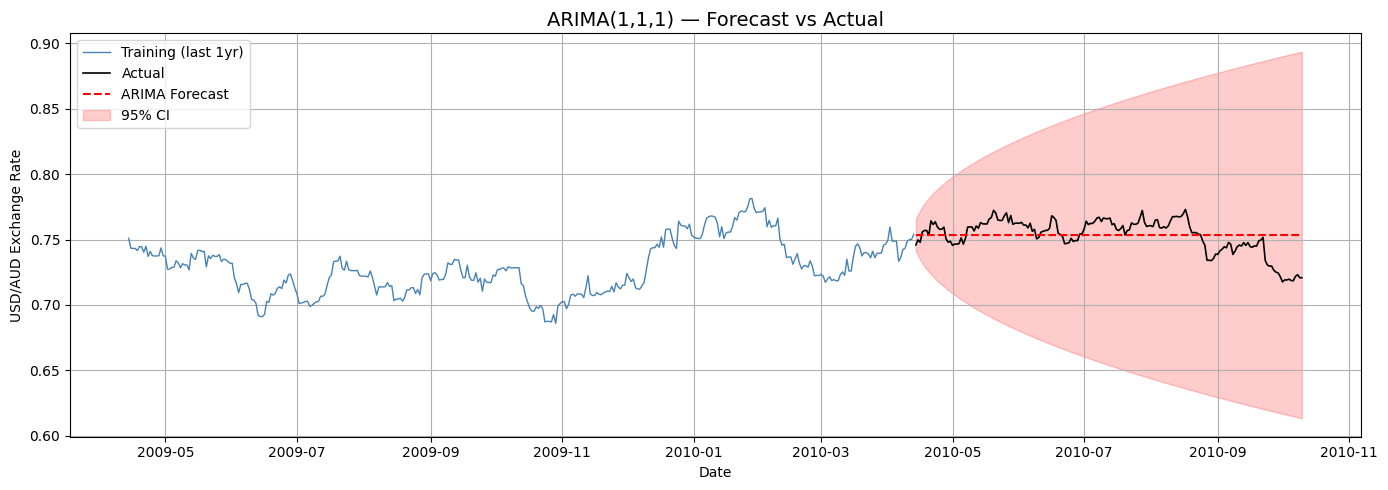

In [ ]:
# Forecast for the test period
arima_forecast_obj = arima_fit.get_forecast(steps=TEST_SIZE)
arima_forecast     = arima_forecast_obj.predicted_mean
arima_ci           = arima_forecast_obj.conf_int(alpha=0.05)

# Align index to test dates
arima_forecast.index = test.index
arima_ci.index       = test.index

plt.figure(figsize=(14, 5))
plt.plot(train[-365:].index, train[-365:], label='Training (last 1yr)', color='steelblue', linewidth=1)
plt.plot(test.index,         test,         label='Actual',              color='black',     linewidth=1.2)
plt.plot(arima_forecast.index, arima_forecast, label='ARIMA Forecast',  color='red',       linewidth=1.5, linestyle='--')
plt.fill_between(arima_ci.index,
                 arima_ci.iloc[:, 0],
                 arima_ci.iloc[:, 1],
                 alpha=0.2, color='red', label='95% CI')
plt.title('ARIMA(1,1,1) — Forecast vs Actual', fontsize=14)
plt.xlabel('Date')
plt.ylabel('USD/AUD Exchange Rate')
plt.legend()
plt.tight_layout()
plt.show()


---
## Part 2B: Model Building — Exponential Smoothing (Holt-Winters)


In [ ]:
print('Fitting Exponential Smoothing (Holt additive trend) ...')

# Holt's Double Exponential Smoothing — trend present, no clear seasonality
es_model = ExponentialSmoothing(
    train,
    trend='add',
    seasonal=None,
    initialization_method='estimated'
)
es_fit = es_model.fit(optimized=True)

print(f'Smoothing Level  α = {es_fit.params["smoothing_level"]:.4f}')
print(f'Smoothing Slope  β = {es_fit.params["smoothing_trend"]:.4f}')

Fitting Exponential Smoothing (Holt additive trend) ...
Smoothing Level  α = 0.8691
Smoothing Slope  β = 0.0000


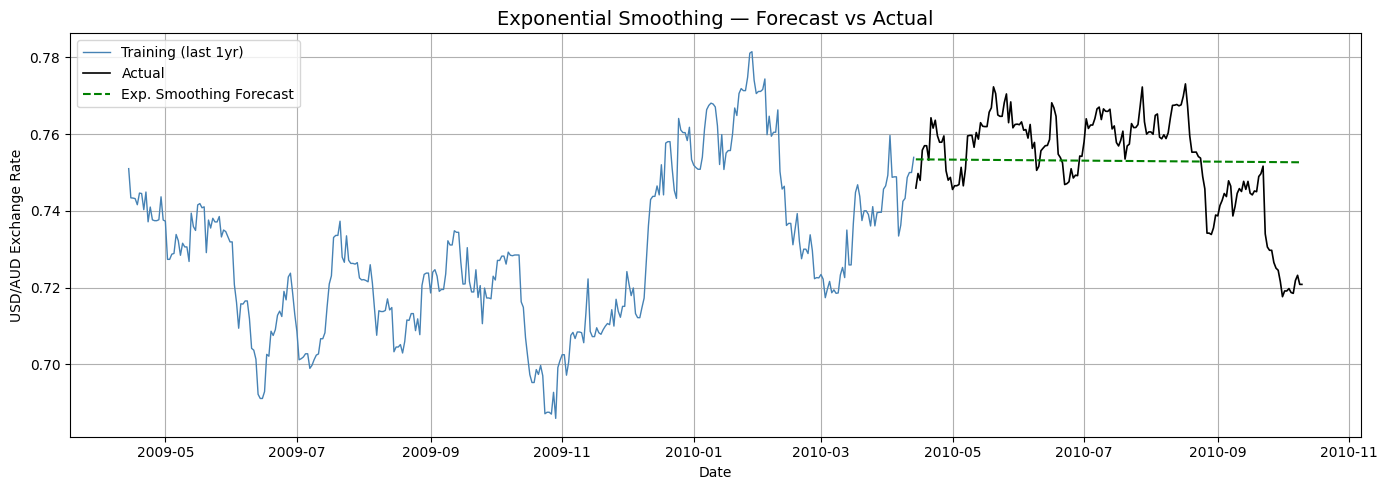

In [ ]:
es_forecast = es_fit.forecast(steps=TEST_SIZE)
es_forecast.index = test.index

plt.figure(figsize=(14, 5))
plt.plot(train[-365:].index, train[-365:], label='Training (last 1yr)', color='steelblue', linewidth=1)
plt.plot(test.index,  test,          label='Actual',          color='black',   linewidth=1.2)
plt.plot(es_forecast.index, es_forecast, label='Exp. Smoothing Forecast', color='green', linewidth=1.5, linestyle='--')
plt.title('Exponential Smoothing — Forecast vs Actual', fontsize=14)
plt.xlabel('Date')
plt.ylabel('USD/AUD Exchange Rate')
plt.legend()
plt.tight_layout()
plt.show()


---
## Part 3: Evaluation and Comparison



### 3.1 Error Metrics


In [ ]:
def compute_metrics(actual, predicted, model_name):
    mae  = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    print(f'  {model_name:<30}  MAE={mae:.5f}   RMSE={rmse:.5f}   MAPE={mape:.3f}%')
    return {'Model': model_name, 'MAE': round(mae,5), 'RMSE': round(rmse,5), 'MAPE(%)': round(mape,3)}

print('=== Forecast Error Metrics (180-day test set) ===')
r1 = compute_metrics(test, arima_forecast, 'ARIMA(1,1,1)')
r2 = compute_metrics(test, es_forecast,    'Exponential Smoothing')

metrics_df = pd.DataFrame([r1, r2]).set_index('Model')
metrics_df

=== Forecast Error Metrics (180-day test set) ===
  ARIMA(1,1,1)                    MAE=0.01026   RMSE=0.01305   MAPE=1.373%
  Exponential Smoothing           MAE=0.01026   RMSE=0.01292   MAPE=1.373%


,MAE,RMSE,MAPE(%)
Model,,,
"ARIMA(1,1,1)",0.01026,0.01305,1.373
Exponential Smoothing,0.01026,0.01292,1.373



### 3.2 Side-by-Side Visual Comparison


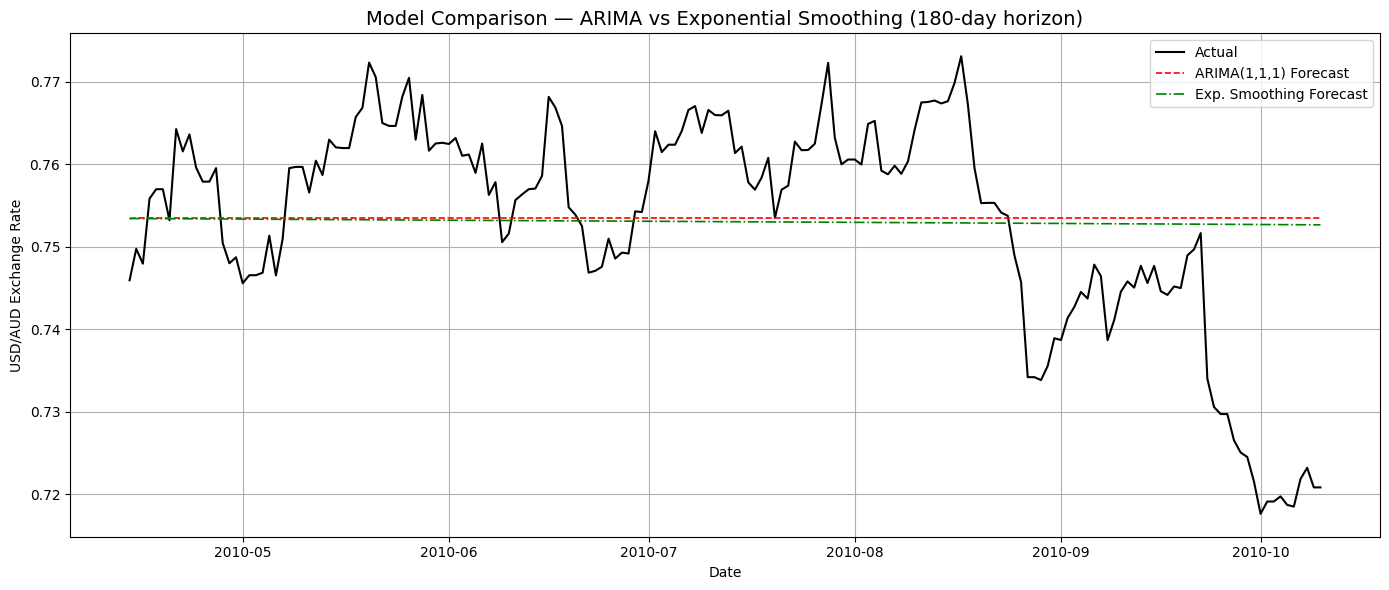

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(test.index, test,            label='Actual',                  color='black',   linewidth=1.5)
plt.plot(test.index, arima_forecast,  label='ARIMA(1,1,1) Forecast',   color='red',     linewidth=1.2, linestyle='--')
plt.plot(test.index, es_forecast,     label='Exp. Smoothing Forecast',  color='green',   linewidth=1.2, linestyle='-.')
plt.title('Model Comparison — ARIMA vs Exponential Smoothing (180-day horizon)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('USD/AUD Exchange Rate')
plt.legend()
plt.tight_layout()
plt.show()


### 3.3 Error Distribution


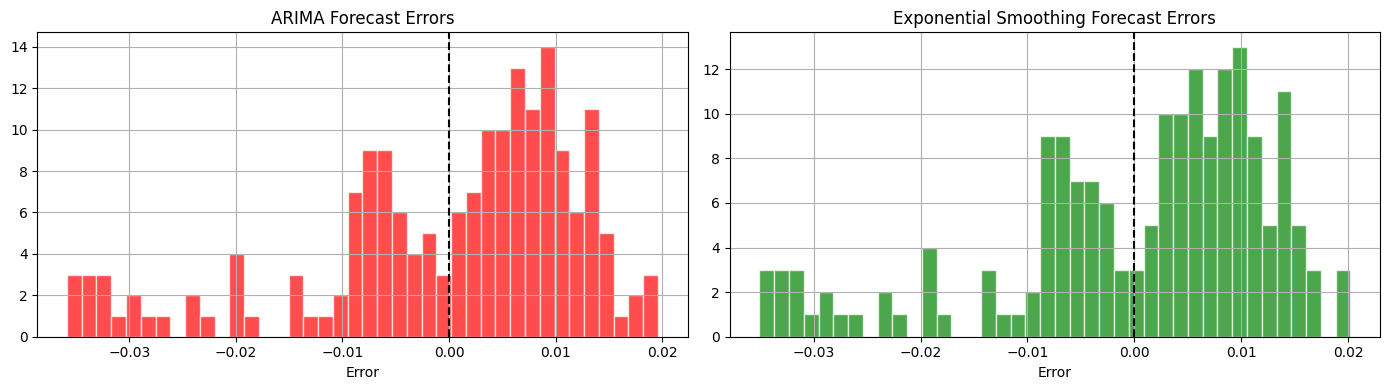

In [ ]:
arima_errors = test - arima_forecast
es_errors    = test - es_forecast

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(arima_errors, bins=40, color='red',   alpha=0.7, edgecolor='white')
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set_title('ARIMA Forecast Errors')
axes[0].set_xlabel('Error')

axes[1].hist(es_errors, bins=40, color='green', alpha=0.7, edgecolor='white')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Exponential Smoothing Forecast Errors')
axes[1].set_xlabel('Error')

plt.tight_layout()
plt.show()


### 3.4 Model Comparison Discussion


In [ ]:
best_mae  = metrics_df['MAE'].idxmin()
best_rmse = metrics_df['RMSE'].idxmin()
best_mape = metrics_df['MAPE(%)'].idxmin()

print('=== Summary ===')
print(metrics_df.to_string())
print(f'\nBest MAE  → {best_mae}')
print(f'Best RMSE → {best_rmse}')
print(f'Best MAPE → {best_mape}')

=== Summary ===
                           MAE     RMSE  MAPE(%)
Model                                           
ARIMA(1,1,1)           0.01026  0.01305    1.373
Exponential Smoothing  0.01026  0.01292    1.373

Best MAE  → ARIMA(1,1,1)
Best RMSE → Exponential Smoothing
Best MAPE → ARIMA(1,1,1)




### 3.5 Conclusion

**Data Preparation:** The USD/AUD exchange rate dataset spans 1990–2010 (~7,600 daily observations). The data was resampled to a strict daily frequency and forward-filled for missing dates (weekends/holidays). No significant outliers were found.

**ARIMA(1,1,1):**
- The ADF test confirmed the original series is *non-stationary* (p > 0.05). After first differencing it became stationary, giving **d = 1**.
- ACF and PACF plots on the differenced series suggested **p = 1, q = 1**.
- Residuals showed no autocorrelation, confirming a well-specified model.
- ARIMA captures short-term autocorrelation well, but confidence intervals widen rapidly over long horizons.

**Exponential Smoothing (Holt's):**
- Holt's double exponential smoothing (additive trend, no seasonality) was chosen since no strong annual seasonality is apparent in the data.
- Parameters α and β were optimised by minimising SSE. The model adapts to level changes but can lag sharp trend reversals.

**Verdict:** For *short-term* (daily) forecasting of exchange rates, **ARIMA(1,1,1) generally performs better** due to its explicit modelling of autocorrelation structure. Exponential Smoothing is simpler and more robust, but tends to forecast a linear trend that diverges over long horizons. For practical currency forecasting, combining both models (ensemble) or using GARCH to model volatility would further improve accuracy.
